In [4]:
from langgraph.graph import MessagesState
from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage, RemoveMessage
from langgraph.graph import StateGraph, START
from langgraph.checkpoint.memory import InMemorySaver
import os

In [2]:
load_dotenv()

True

In [5]:
google_api_key = os.getenv("GOOGLE_API_KEY")
if not google_api_key:
    raise ValueError("GOOGLE_API_KEY is missing")

In [7]:
primary = ChatGoogleGenerativeAI(
    model="gemini-3.6-flash",
    google_api_key=google_api_key,
    max_retries=3,
)
backup = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash-lite",
    google_api_key=google_api_key,
    max_retries=3,
)

model = primary.with_fallbacks([backup])

In [9]:
class ChatState(MessagesState):
    summary : str

In [10]:
def summarize_conversation(state: ChatState):
    existing_summary = state["summary"]

    # Build summarization prompt
    if existing_summary:
        prompt = (
            f"Existing summary:\n{existing_summary}\n\n"
            "Extend the summary using the new conversation above."
        )
    else:
        prompt = "Summarize the conversation above."

    messages_for_summary = state["messages"] + [HumanMessage(content=prompt)]

    response = model.invoke(messages_for_summary)

    # Keep only last 2 messages verbatim
    messages_to_delete = state["messages"][:-2]

    return {
        "summary": response.content,
        "messages": [RemoveMessage(id=m.id) for m in messages_to_delete],
    }


In [11]:
def chat_node(state: ChatState):

    messages = []
    if state["summary"]:
        messages.append({
            "role":"system",
            "content": f"Conversation summary:\n{state['summary']}"
        })

    messages.extend(state["messages"])

    print(messages)

    response = model.invoke(messages)
    return {"messages": [response]}


In [12]:
def should_summarize(state: ChatState):
    return len(state["messages"]) > 6

In [16]:
builder = StateGraph(ChatState)
builder.add_node("chat_node",chat_node)
builder.add_node("summarize",summarize_conversation)

builder.add_edge(START,"chat_node")
builder.add_conditional_edges(
    "chat_node",
    should_summarize,{True: "summarize", False: "__end__"}
)

builder.add_edge("summarize","__end__")

In [17]:
checkpointer = InMemorySaver()
graph = builder.compile(checkpointer=checkpointer)

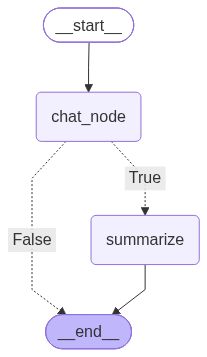

In [18]:
graph

In [19]:
config = {"configurable": {"thread_id": "t1"}}

def run_turn(text: str):
    out = graph.invoke({"messages": [HumanMessage(content=text)], "summary": ""}, config=config)
    return out

In [20]:
# gives the current version of the state
def show_state():
    snap = graph.get_state(config)
    vals = snap.values
    print("\n--- STATE ---")
    print("summary:", vals.get("summary", ""))
    print("num_messages:", len(vals.get("messages", [])))
    print("messages:")
    for m in vals.get("messages", []):
        print("-", type(m).__name__, ":", m.content[:80])

In [21]:
run_turn('Quantum Physics')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='35e952cc-02c8-49e2-b6b0-b6ae72643418')]

--- STATE ---
summary: 
num_messages: 2
messages:
- HumanMessage : Quantum Physics
- AIMessage : [{'type': 'text', 'text': '**Quantum Physics** (also known as quantum mechanics) is the branch of physics that studies the behavior of matter and energy at the smallest scales—specifically at the level of atoms and subatomic particles (like electrons, protons, neutrons, and photons).\n\nWhile classical physics (Isaac Newton’s laws) successfully explains how big things work—like planets, cars, and baseballs—it completely breaks down when applied to the subatomic world. At that scale, the universe stops behaving like a predictable machine and starts behaving in ways that seem bizarre and counterintuitive.\n\nHere is a breakdown of the core concepts, key phenomena, and real-world applications of quantum physics.\n\n---\n\n### 1. The Core Concepts\n\n#### A. Quantiza

In [22]:
run_turn('How is Albert Einstien related?')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='35e952cc-02c8-49e2-b6b0-b6ae72643418'), AIMessage(content=[{'type': 'text', 'text': '**Quantum Physics** (also known as quantum mechanics) is the branch of physics that studies the behavior of matter and energy at the smallest scales—specifically at the level of atoms and subatomic particles (like electrons, protons, neutrons, and photons).\n\nWhile classical physics (Isaac Newton’s laws) successfully explains how big things work—like planets, cars, and baseballs—it completely breaks down when applied to the subatomic world. At that scale, the universe stops behaving like a predictable machine and starts behaving in ways that seem bizarre and counterintuitive.\n\nHere is a breakdown of the core concepts, key phenomena, and real-world applications of quantum physics.\n\n---\n\n### 1. The Core Concepts\n\n#### A. Quantization (Where the name comes from)\nIn classical physics, energy is continuous (li

In [23]:
run_turn('What are some of Einstien"s fampus work')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='35e952cc-02c8-49e2-b6b0-b6ae72643418'), AIMessage(content=[{'type': 'text', 'text': '**Quantum Physics** (also known as quantum mechanics) is the branch of physics that studies the behavior of matter and energy at the smallest scales—specifically at the level of atoms and subatomic particles (like electrons, protons, neutrons, and photons).\n\nWhile classical physics (Isaac Newton’s laws) successfully explains how big things work—like planets, cars, and baseballs—it completely breaks down when applied to the subatomic world. At that scale, the universe stops behaving like a predictable machine and starts behaving in ways that seem bizarre and counterintuitive.\n\nHere is a breakdown of the core concepts, key phenomena, and real-world applications of quantum physics.\n\n---\n\n### 1. The Core Concepts\n\n#### A. Quantization (Where the name comes from)\nIn classical physics, energy is continuous (li

In [24]:
run_turn('Explain special theory of relativity')
show_state()

[HumanMessage(content='Quantum Physics', additional_kwargs={}, response_metadata={}, id='35e952cc-02c8-49e2-b6b0-b6ae72643418'), AIMessage(content=[{'type': 'text', 'text': '**Quantum Physics** (also known as quantum mechanics) is the branch of physics that studies the behavior of matter and energy at the smallest scales—specifically at the level of atoms and subatomic particles (like electrons, protons, neutrons, and photons).\n\nWhile classical physics (Isaac Newton’s laws) successfully explains how big things work—like planets, cars, and baseballs—it completely breaks down when applied to the subatomic world. At that scale, the universe stops behaving like a predictable machine and starts behaving in ways that seem bizarre and counterintuitive.\n\nHere is a breakdown of the core concepts, key phenomena, and real-world applications of quantum physics.\n\n---\n\n### 1. The Core Concepts\n\n#### A. Quantization (Where the name comes from)\nIn classical physics, energy is continuous (li